# 11 · Bayesian IRT training

Does a better-trained IRT model give better score predictions? The baseline trains IRT by
gradient descent on an L2-penalised likelihood (`fit_mirt`): one point estimate per parameter.
Here we swap in the hierarchical Bayesian model that tinyBenchmarks fits with py-irt
(`fit_mirt_bayes`): Gaussian priors on abilities and item parameters, prior means and
scales learned from the data, fitted by variational inference, posterior means used.

Everything else is fixed: same 5 family splits, 20 seeds, k, selectors, estimators, and
dimension (D=1 for the 05 methods, D=3 for adaptive MIRT as chosen in 06).
Results come from `scripts/irt/run_bayesian.py`; the gradient-descent side is the saved
05 / 07 output (the script checks it still reproduces). Style follows `design.md`.

In [1]:
import sys

sys.path.insert(0, "../scripts/irt")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from efficbench import ROOT

N_ITEMS = 14042
FIGS = ROOT / "results/figures"
FIGS.mkdir(parents=True, exist_ok=True)
PROG, BAYES = ROOT / "results/irt/progression", ROOT / "results/irt/bayesian"

STYLE = {  # fit: (colour, marker, line style), from design.md; our change is navy
    "gradient descent": ("#93C5FD", "^", "--"),
    "bayesian": ("#1E3A8A", "o", "-"),
}
LABEL = {"gradient descent": "Gradient descent (baseline)", "bayesian": "Bayesian (ours)"}
PANELS = {  # title: (gradient-descent stage, bayesian stage, method)
    "IRT prediction only\n(random questions, 1D)": ("information", "d1", "random + p-IRT"),
    "tinyBenchmarks IRT\n(anchors + blend, 1D)": ("information", "d1", "IRT anchors + gp-IRT"),
    "Adaptive MIRT\n(V-optimal + blend, 3D)": ("voptimal", "d3", "voptimal_adaptive + gp-IRT"),
}
plt.rcParams.update(
    {
        "font.size": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.alpha": 0.3,
        "legend.frameon": False,
    }
)

## Load

Per-model predictions for both fits, joined so every row is the same model, split, seed and k.

In [2]:
def records(path, method, fit):
    d = pd.read_csv(path, usecols=["split", "k", "seed", "method", "model_id", "abs_error"])
    return d[d.method == method].assign(fit=fit)


rows = []
for title, (gd_stage, b_stage, method) in PANELS.items():
    gd = records(PROG / gd_stage / "predictions.csv", method, "gradient descent")
    b = records(BAYES / b_stage / "predictions.csv", method, "bayesian")
    rows.append(pd.concat([gd, b]).assign(panel=title))
pred = pd.concat(rows, ignore_index=True)

# MAE per split (seeds and models averaged), percentage points
mae = pred.groupby(["panel", "fit", "k", "split"]).abs_error.mean().mul(100)
summary = mae.groupby(["panel", "fit", "k"]).agg(["mean", "std"]).round(2)
summary.unstack("fit")

mean                   \
fit                                             bayesian gradient descent   
panel                                       k                               
Adaptive MIRT\n(V-optimal + blend, 3D)      10      3.65             3.73   
                                            20      2.47             2.40   
                                            50      1.69             1.64   
                                            100     1.55             1.57   
                                            200     1.32             1.44   
                                            500     1.24             1.25   
IRT prediction only\n(random questions, 1D) 10      5.93             5.79   
                                            20      4.57             4.49   
                                            50      3.17             3.18   
                                            100     2.57             2.56   
                                            200     2.09             1.99   
                                            500     1.74             1.63   
tinyBenchmarks IRT\n(anchors + blend, 1D)   10      5.11             5.36   
                                            20      4.19             4.39   
                                            50      2.90             2.99   
                                            100     2.31             2.28   
                                            200     1.80             1.82   
                                            500     1.34             1.38   

                                                     std                   
fit                                             bayesian gradient descent  
panel                                       k                              
Adaptive MIRT\n(V-optimal + blend, 3D)      10      0.98             0.77  
                                            20      0.63             0.55  
                                            50      0.33             0.30  
                                            100     0.29             0.16  
                                            200     0.23             0.14  
                                            500     0.19             0.16  
IRT prediction only\n(random questions, 1D) 10      0.83             0.89  
                                            20      0.50             0.57  
                                            50      0.48             0.54  
                                            100     0.50             0.52  
                                            200     0.63             0.53  
                                            500     0.71             0.57  
tinyBenchmarks IRT\n(anchors + blend, 1D)   10      0.71             0.71  
                                            20      0.45             0.57  
                                            50      0.37             0.47  
                                            100     0.49             0.47  
                                            200     0.35             0.43  
                                            500     0.26             0.29

## 1 · Score error with each training method

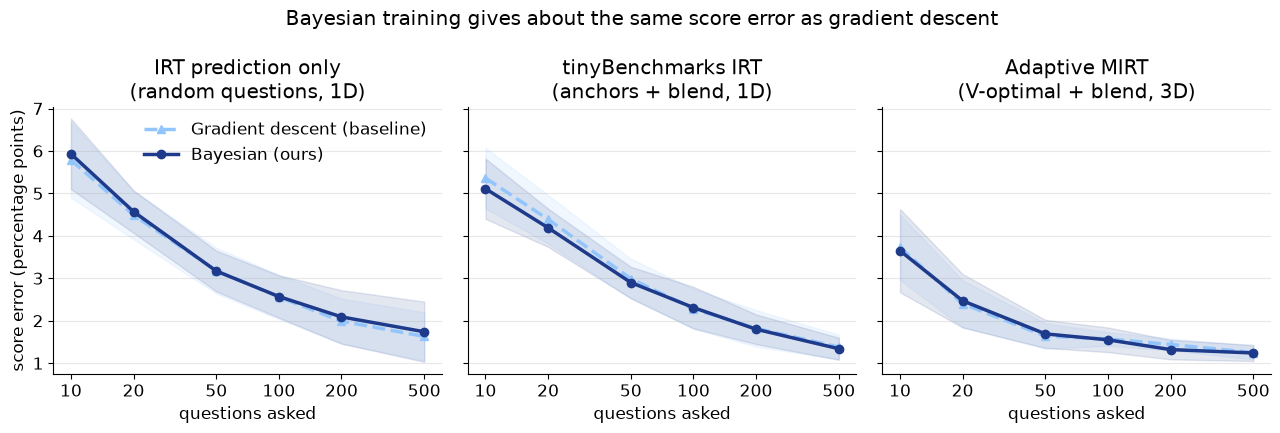

In [3]:
fig, axes = plt.subplots(1, len(PANELS), figsize=(13, 4.4), sharey=True)
for ax, title in zip(axes, PANELS, strict=True):
    for fit, (colour, marker, ls) in STYLE.items():
        s = summary.loc[(title, fit)]
        ax.plot(s.index, s["mean"], marker=marker, ls=ls, color=colour, lw=2.5, label=LABEL[fit])
        ax.fill_between(
            s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=colour, alpha=0.12
        )
    ks = s.index
    ax.set(xscale="log", title=title, xlabel="questions asked")
    ax.set_xticks(ks, ks)
    ax.minorticks_off()
axes[0].set_ylabel("score error (percentage points)")
axes[0].legend()
fig.suptitle("Bayesian training gives about the same score error as gradient descent")
fig.tight_layout()
fig.savefig(FIGS / "bayesian_error_vs_questions.png", dpi=200)

## 2 · Paired improvement

For every held-out model, split, seed and k: gradient-descent error minus Bayesian error.
Above zero means the Bayesian fit predicted that model's score better. Mean per split,
then mean ±1 SD across the 5 splits.

In [4]:
keys = ["panel", "split", "k", "seed", "model_id"]
wide = pred.pivot_table(index=keys, columns="fit", values="abs_error")
gain = (wide["gradient descent"] - wide["bayesian"]).mul(100)
gain_split = gain.groupby(["panel", "k", "split"]).mean()
g = gain_split.groupby(["panel", "k"]).agg(["mean", "std"])
share = (gain > 0).groupby(["panel", "k"]).mean().mul(100).rename("models better (%)")
pd.concat([g.round(2), share.round(0)], axis=1).unstack("panel")

mean  \
panel Adaptive MIRT\n(V-optimal + blend, 3D)   
k                                              
10                                      0.08   
20                                     -0.07   
50                                     -0.04   
100                                     0.02   
200                                     0.11   
500                                     0.02   

                                                   \
panel IRT prediction only\n(random questions, 1D)   
k                                                   
10                                          -0.14   
20                                          -0.08   
50                                           0.01   
100                                         -0.01   
200                                         -0.10   
500                                         -0.10   

                                                 \
panel tinyBenchmarks IRT\n(anchors + blend, 1D)   
k                                                 
10                                         0.25   
20                                         0.21   
50                                         0.09   
100                                       -0.03   
200                                        0.02   
500                                        0.04   

                                         std  \
panel Adaptive MIRT\n(V-optimal + blend, 3D)   
k                                              
10                                      0.92   
20                                      0.37   
50                                      0.30   
100                                     0.23   
200                                     0.24   
500                                     0.14   

                                                   \
panel IRT prediction only\n(random questions, 1D)   
k                                                   
10                                           0.18   
20                                           0.15   
50                                           0.19   
100                                          0.25   
200                                          0.42   
500                                          0.43   

                                                 \
panel tinyBenchmarks IRT\n(anchors + blend, 1D)   
k                                                 
10                                         0.38   
20                                         0.20   
50                                         0.18   
100                                        0.27   
200                                        0.14   
500                                        0.05   

                           models better (%)  \
panel Adaptive MIRT\n(V-optimal + blend, 3D)   
k                                              
10                                      52.0   
20                                      47.0   
50                                      50.0   
100                                     47.0   
200                                     55.0   
500                                     48.0   

                                                   \
panel IRT prediction only\n(random questions, 1D)   
k                                                   
10                                           44.0   
20                                           47.0   
50                                           52.0   
100                                          53.0   
200                                          52.0   
500                                          52.0   

                                                 
panel tinyBenchmarks IRT\n(anchors + blend, 1D)  
k                                                
10                                         52.0  
20                                         52.0  
50                                         51.0  
100                                        50.0  
200                                  

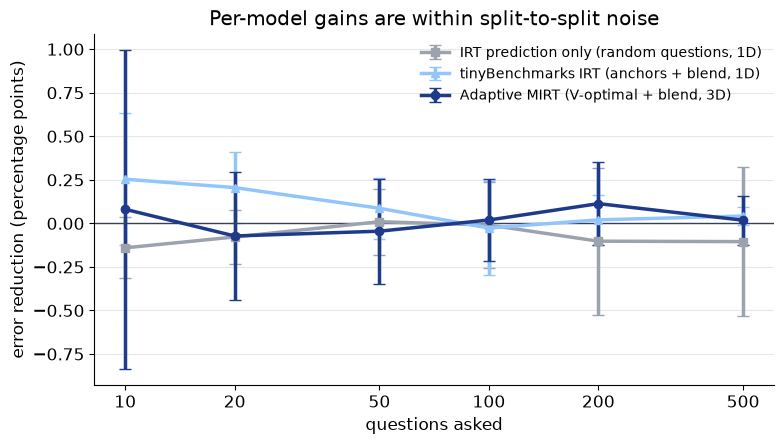

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.6))
markers = ["s", "^", "o"]
colours = ["#9CA3AF", "#93C5FD", "#1E3A8A"]
for title, marker, colour in zip(PANELS, markers, colours, strict=True):
    s = g.loc[title]
    ax.errorbar(
        s.index,
        s["mean"],
        yerr=s["std"],
        marker=marker,
        color=colour,
        lw=2.5,
        capsize=4,
        label=title.replace("\n", " "),
    )
ax.axhline(0, color="#374151", lw=1)
ax.set(
    xscale="log",
    xlabel="questions asked",
    ylabel="error reduction (percentage points)",
    title="Per-model gains are within split-to-split noise",
)
ax.set_xticks(s.index, s.index)
ax.minorticks_off()
ax.legend(fontsize=10)
fig.tight_layout()
fig.savefig(FIGS / "bayesian_paired_gain.png", dpi=200)

## 3 · Is the Bayesian model a better model of the answers?

Separate from score error: reveal half of each held-out model's answers, predict the other
half. Lower log loss / Brier is better; ECE is calibration error (0 is perfect).

In [6]:
answers = pd.read_csv(BAYES / "answers.csv").query("predictor == 'IRT'")
answers.groupby(["n_dims", "fit"])[["log_loss", "brier", "ece"]].agg(["mean", "std"]).round(4)

log_loss           brier             ece        
                            mean     std    mean     std    mean     std
n_dims fit                                                              
1      bayesian           0.4309  0.0379  0.1411  0.0136  0.0148  0.0081
       gradient descent   0.4304  0.0373  0.1409  0.0134  0.0160  0.0060
3      bayesian           0.4058  0.0382  0.1326  0.0139  0.0084  0.0032
       gradient descent   0.4050  0.0389  0.1323  0.0141  0.0083  0.0022

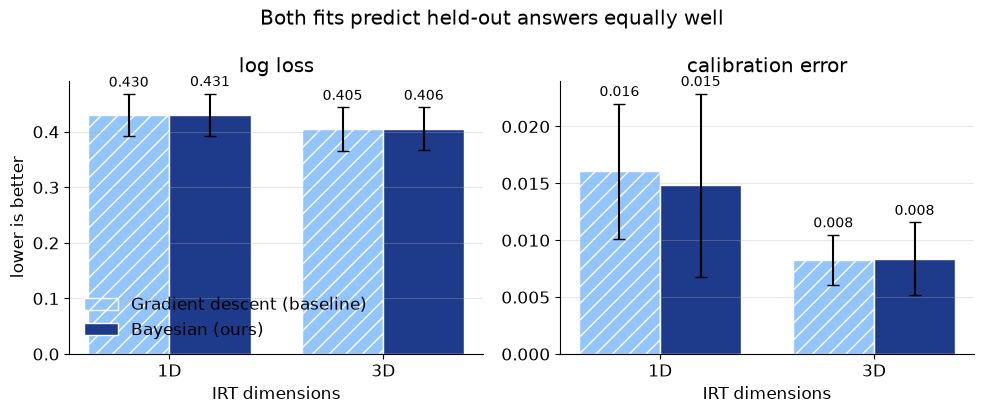

In [7]:
metrics = {"log_loss": "log loss", "ece": "calibration error"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
a = answers.groupby(["n_dims", "fit"])[list(metrics)].agg(["mean", "std"])
dims = sorted(answers.n_dims.unique())
x = np.arange(len(dims))
for ax, (col, name) in zip(axes, metrics.items(), strict=True):
    for i, (fit, (colour, _, _)) in enumerate(STYLE.items()):
        m = a.xs(fit, level="fit")[col]
        bars = ax.bar(
            x + (i - 0.5) * 0.38,
            m["mean"],
            0.38,
            yerr=m["std"],
            capsize=4,
            color=colour,
            label=LABEL[fit],
            hatch="//" if fit == "gradient descent" else None,
            edgecolor="white",
        )
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=10)
    ax.set_xticks(x, [f"{d}D" for d in dims])
    ax.set(title=name, xlabel="IRT dimensions")
axes[0].set_ylabel("lower is better")
axes[0].legend(loc="lower left")
fig.suptitle("Both fits predict held-out answers equally well")
fig.tight_layout()
fig.savefig(FIGS / "bayesian_answer_fit.png", dpi=200)